# Milestone 2 — Modellreife & Validierung

Aufbauend auf der Baseline (`baseline_model.ipynb`, siehe `MILESTONE1_REPORT.md`: Crop Balanced Accuracy 0.778, Stage 0.769). Dieses Notebook überarbeitet die Preprocessing-Pipeline (Spektral-Interpolation statt globalem Median, zyklisches Month-Encoding, Stratifizierung auf Crop+Stage), ergänzt **Feature Engineering** (Vegetationsindizes, Red-Edge, Gradienten, Spektral-Statistiken — übernommen und überarbeitet aus `features.ipynb`) und ersetzt den einfachen Train/Test-Split durch 5-fache Cross-Validation inkl. Modellvergleich (RandomForest vs. HistGradientBoosting vs. MLP), Overfitting-Check (Train vs. CV), Hyperparameter-Tuning mit gleichem Budget für HGB und MLP, **Strategievergleich** (separate Modelle vs. gemeinsames Label `Crop|Stage`) und Fehleranalyse (Confusion Matrix pro Klasse).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
df = pd.read_csv('train.csv')

## Preprocessing v2

**Spektral-NaN-Handling:** Wie in M1 werden die 67 komplett leeren Spektralband-Spalten verworfen. Für die verbleibenden 6 Spalten mit vereinzelten Lücken (max. 24 von 5591 Zeilen) nutzen wir statt globalem Spalten-Median eine **zeilenweise lineare Interpolation entlang der Wellenlänge**: die Spaltennamen (`X<nm>`) kodieren die Wellenlänge, Reflektanzspektren verlaufen glatt über benachbarte Bänder, daher lässt sich eine fehlende Bande besser aus den Nachbarbändern *derselben Messung* schätzen als aus dem Median über alle Messungen. Die Interpolation ist zeilenlokal (nutzt nur Werte derselben Zeile) → kein Leakage zwischen Train/Test, kann also vor dem Split angewendet werden. Ein `SimpleImputer(median)` bleibt zusätzlich als Absicherung in der Pipeline für etwaige Restfälle (Rand-NaNs ohne Nachbarn in einer Richtung).

In [2]:
spec_cols = [c for c in df.columns if c.startswith('X')]
na_frac = df[spec_cols].isna().mean()
usable_spec_cols = sorted([c for c in spec_cols if na_frac[c] < 1.0], key=lambda c: int(c[1:]))
print(f'Nutzbare Spektralbaender: {len(usable_spec_cols)} von {len(spec_cols)}')

df[usable_spec_cols] = df[usable_spec_cols].interpolate(method='linear', axis=1, limit_direction='both')
remaining_na = df[usable_spec_cols].isna().sum().sum()
print('Verbleibende NaNs in Spektralbaendern nach Interpolation:', remaining_na)
assert remaining_na == 0, 'Unerwartete NaNs nach Interpolation -- SimpleImputer-Sicherheitsnetz greift in der Pipeline'

Nutzbare Spektralbaender: 131 von 198
Verbleibende NaNs in Spektralbaendern nach Interpolation: 0


## Feature Engineering

Aus den interpolierten Spektren werden zusätzliche, **rein zeilenlokale** Features berechnet (nutzen nur Werte derselben Messung → kein Leakage, vor dem Split zulässig und später 1:1 auf `test.csv` anwendbar). Bänder werden per nächstgelegener Wellenlänge gewählt, Reflektanz liegt in Prozent (0–93).

Übernommen aus `features.ipynb`:
- **Spektral-Statistiken:** mean, std (neu), max, min, Amplitude; Position von Max/Min als **Wellenlänge** (statt Bandabstand, der über die entfernten Wasserbänder hinweg verzerrt ist).
- **Vegetationsindizes:** NDVI, Simple Ratio NIR/Rot, NDMI (NIR/SWIR1), NBR (NIR/SWIR2), ND NIR2/SWIR1, EVI (Konstante auf Prozent-Skala angepasst).
- **Gradienten:** max. positive/negative Steigung und totale Variation — hier **pro nm** (`Δ Reflektanz / Δ λ`), sonst dominieren die Sprünge an den Lücken (923→983, 1094→1175, 1316→1518, 1760→2063 nm).
- **AEZ One-Hot:** für das MLP sinnvoll (AEZ ist kategorial), für Bäume neutral.

Neu (domänenspezifisch; die Aufgabenstellung betont Red-Edge und SWIR, zielt v. a. auf die schwachen Reife-/Erntestadien):
- **Red-Edge:** NDRE (790/720), CI red-edge (783/712 − 1), Red-Edge-Position (lineare Interpolation nach Guyot & Baret, 670/700/740/780 nm) — Chlorophyllgehalt, verschiebt sich mit dem Wachstumsstadium.
- **PSRI** (680 − 500)/750 — Plant Senescence Reflectance Index, Seneszenz/Reife.
- **PRI** (531/570) — Photosynthese-Effizienz; **NDWI nach Gao** (860/1240) — Blattwassergehalt.

Bewusst **nicht** übernommen aus `features.ipynb`: die 46 normierten Differenzen/Ratios an Prozent-Positionen des Spektrums (b10…b90 — Positionen ohne physikalische Bedeutung, mehrere davon Duplikate bzw. Kehrwerte voneinander; die Domänen-Indizes decken das fachlich begründet ab) und die Breiten der Hoch-/Tiefbereiche (in Bandanzahl gemessen, über die Lücken hinweg irreführend).

In [ ]:
def add_features(df, cols):
    """Zeilenlokale Spektral-Features. cols: nach Wellenlaenge sortierte, interpolierte Bandspalten."""
    S = df[cols].to_numpy(float)
    wl = np.array([int(c[1:]) for c in cols], dtype=float)
    def b(nm):  # Reflektanz des Bandes mit der naechsten Wellenlaenge
        return S[:, np.abs(wl - nm).argmin()]
    def nd(a, c):
        return (a - c) / (a + c)

    blue, red, nir, nir2, swir1, swir2 = b(490), b(660), b(850), b(1100), b(1640), b(2200)
    slope = np.diff(S, axis=1) / np.diff(wl)  # pro nm
    r670, r700, r740, r780 = b(670), b(700), b(740), b(780)
    f = {
        # Statistiken
        'spec_mean': S.mean(1), 'spec_std': S.std(1), 'spec_max': S.max(1), 'spec_min': S.min(1),
        'spec_amplitude': S.max(1) - S.min(1), 'wl_of_max': wl[S.argmax(1)], 'wl_of_min': wl[S.argmin(1)],
        # Vegetationsindizes
        'NDVI': nd(nir, red), 'SR_NIR_Red': nir / red, 'NDMI': nd(nir, swir1), 'NBR': nd(nir, swir2), #grüne lebende Biomasse, reagiert stärker als ndvi, feuchte im blatt, trockene pflanzenmassen 
        'ND_NIR2_SWIR1': nd(nir2, swir1), #wasser und trockenmasse
        'EVI': 2.5 * (nir - red) / (nir + 6 * red - 7.5 * blue + 100),  # Reflektanz in %, daher +100 statt +1 korrigiert bodeneinfluss und dunst besserer ndvi
        # Gradienten
        'max_pos_slope': slope.max(1), 'max_neg_slope': slope.min(1), 'total_variation': np.abs(slope).sum(1),
        # Red-Edge, Seneszenz, Wasser
        'NDRE': nd(b(790), b(720)), 'CI_rededge': b(783) / b(712) - 1, #gut für späte und mittlere stadien (sättigt später)
        'REP': 700 + 40 * ((r670 + r780) / 2 - r700) / (r740 - r700),
        'PSRI': (b(680) - b(500)) / b(750), 'PRI': nd(b(531), b(570)), 'NDWI_Gao': nd(b(860), b(1240)),#schwache stadien, zeigt stress, blattwasser gehalt
    }
    return pd.DataFrame(f, index=df.index).replace([np.inf, -np.inf], np.nan)

eng = add_features(df, usable_spec_cols)
aez_onehot = pd.get_dummies(df['AEZ'], prefix='AEZ', dtype=float)
eng_cols = list(eng.columns) + list(aez_onehot.columns)
df = pd.concat([df, eng, aez_onehot], axis=1).copy()
print(f'{eng.shape[1]} Spektral-Features + {aez_onehot.shape[1]} AEZ-One-Hot-Spalten, NaN/inf: {int(eng.isna().sum().sum())}')
eng.describe().T[['mean', 'min', 'max']].round(3)

22 Spektral-Features + 7 AEZ-One-Hot-Spalten, NaN/inf: 0


,mean,min,max
spec_mean,26.639,12.034,50.618
spec_std,11.968,2.157,28.258
spec_max,48.865,18.689,93.232
spec_min,9.592,0.252,27.963
spec_amplitude,39.273,10.244,86.671
wl_of_max,1128.179,437.000,2143.000
wl_of_min,1748.666,447.000,2345.000
NDVI,0.485,0.059,0.877
SR_NIR_Red,4.232,1.127,15.273
NDMI,0.178,-0.301,0.614


**Month-Encoding:** `Month` reicht im Datensatz nur von 5 (Mai) bis 10 (Oktober) — es gibt keinen Jahreswechsel (Dez→Jan), den eine zyklische Kodierung eigentlich auflösen soll. Zyklisches Encoding ist hier also theoretisch nicht zwingend notwendig; wir testen es trotzdem empirisch per Cross-Validation gegen die einfache numerische Variante (siehe Modellvergleich unten) und werten anhand des CV-Scores, ob es einen messbaren Unterschied macht.

In [4]:
print('Month-Wertebereich:', df['Month'].min(), '-', df['Month'].max())
df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12)

Month-Wertebereich: 5 - 10


**Kombinierter Stratifizierungs-Key:** Die Baseline stratifizierte nur auf `Crop` — laut Feedback soll `Stage` ebenfalls berücksichtigt werden. Da `Stage` inhaltlich eine Unterkategorie innerhalb von `Crop` ist (vgl. Aufgabenstellung, z. B. `corn_early`), bilden wir den kombinierten Key `Crop_Stage` und stratifizieren darauf — das erhält gleichzeitig die Verteilung von `Crop` und von `Stage` in Train/Test und in jedem CV-Fold.

In [5]:
df['Crop_Stage'] = df['Crop'] + '|' + df['Stage']  # '|' als Trenner: Stage-Namen enthalten selbst '_'
combo_counts = df['Crop_Stage'].value_counts()
print(f"{len(combo_counts)} Crop x Stage Kombinationen, kleinste: {combo_counts.idxmin()} mit {combo_counts.min()} Zeilen")
pd.crosstab(df['Crop'], df['Stage'])

23 Crop x Stage Kombinationen, kleinste: cotton|Harvest mit 11 Zeilen


Stage,Critical,Early_Mid,Emerge_VEarly,Harvest,Late,Mature_Senesc
Crop,,,,,,
corn,675,212,152,102,557,399
cotton,158,253,172,11,0,65
rice,0,52,0,0,41,0
soybean,652,465,106,67,233,146
winter_wheat,56,0,608,0,30,379


## Split

Hauptsplit bleibt 70/30 (Vergleichbarkeit mit M1), jetzt aber stratifiziert auf `Crop_Stage`. Zusätzlich prüfen wir kurz, ob andere Split-Verhältnisse (80/20, 90/10) das Ergebnis spürbar verändern.

In [6]:
feature_cols_plain = usable_spec_cols + ['AEZ', 'Month']
feature_cols_cyclic = usable_spec_cols + ['AEZ', 'Month_sin', 'Month_cos']
feature_cols_fe = usable_spec_cols + ['Month'] + eng_cols

y_crop = df['Crop']
y_stage = df['Stage']
combo = df['Crop_Stage']

train_idx, test_idx = train_test_split(df.index, test_size=0.3, stratify=combo, random_state=RANDOM_STATE)

feature_sets = {
    name: {'train': df.loc[train_idx, cols], 'test': df.loc[test_idx, cols]}
    for name, cols in [('plain_month', feature_cols_plain), ('cyclic_month', feature_cols_cyclic), ('plain_month+fe', feature_cols_fe)]
}

y_crop_train, y_crop_test = y_crop.loc[train_idx], y_crop.loc[test_idx]
y_stage_train, y_stage_test = y_stage.loc[train_idx], y_stage.loc[test_idx]
combo_train, combo_test = combo.loc[train_idx], combo.loc[test_idx]
targets = {'Crop': y_crop_train, 'Stage': y_stage_train}

for name, fs in feature_sets.items():
    print(f"{name:15s} Train: {fs['train'].shape}  Test: {fs['test'].shape}")

plain_month     Train: (3913, 133)  Test: (1678, 133)
cyclic_month    Train: (3913, 134)  Test: (1678, 134)
plain_month+fe  Train: (3913, 161)  Test: (1678, 161)


**Sensitivität gegenüber Split-Verhältnis:** Schnelle Kontrolle mit RandomForest (Default-Hyperparameter, plain Month), ob 70/30 gegenüber anderen gängigen Verhältnissen stark abweicht.

In [7]:
def quick_pipeline():
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('clf', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
    ])

ratio_rows = []
for test_size in [0.3, 0.2, 0.1]:
    tr_idx, te_idx = train_test_split(df.index, test_size=test_size, stratify=combo, random_state=RANDOM_STATE)
    crop_fit = quick_pipeline().fit(df.loc[tr_idx, feature_cols_plain], y_crop.loc[tr_idx])
    stage_fit = quick_pipeline().fit(df.loc[tr_idx, feature_cols_plain], y_stage.loc[tr_idx])
    ratio_rows.append({
        'test_size': test_size,
        'crop_balanced_accuracy': balanced_accuracy_score(y_crop.loc[te_idx], crop_fit.predict(df.loc[te_idx, feature_cols_plain])),
        'stage_balanced_accuracy': balanced_accuracy_score(y_stage.loc[te_idx], stage_fit.predict(df.loc[te_idx, feature_cols_plain])),
    })

ratio_results = pd.DataFrame(ratio_rows)
ratio_results

,test_size,crop_balanced_accuracy,stage_balanced_accuracy
0,0.3,0.830306,0.811420
1,0.2,0.832121,0.825356
2,0.1,0.836795,0.838587


## Cross-Validation & Modellvergleich

5-fache `StratifiedKFold` auf dem `Crop_Stage`-Key des Trainingssplits — dieselbe Fold-Einteilung wird für alle Modelle und Zielgrößen verwendet. Verglichen werden `RandomForestClassifier` (Baseline-Konfiguration), `HistGradientBoostingClassifier` (scikit-learn, kein Zusatzpaket) und ein `MLPClassifier`, auf drei Feature-Sets: Rohbänder mit plain bzw. zyklischem Month und Rohbänder + Feature Engineering (`plain_month+fe`). Der Vergleich Rohbänder vs. `+fe` ist die Ablation, ob das Feature Engineering etwas bringt.

Alle Modelle laufen hier mit **Default-Hyperparametern** — das ist eine Vorauswahl, kein fairer Endvergleich: das MLP reagiert deutlich stärker auf seine Hyperparameter als die Baummodelle. Der faire Vergleich folgt im Abschnitt *Hyperparameter-Tuning*. Das MLP läuft aus Laufzeitgründen nur auf dem `+fe`-Set (es profitiert als einziges Modell von One-Hot-AEZ und Skalierung, und auf Rohbändern gibt es bereits RF/HGB als Referenz).

**Overfitting-Check:** `return_train_score=True` liefert zusätzlich die Balanced Accuracy auf den Trainingsfolds; `gap` = Train − CV. Eine hohe Train-Accuracy allein ist bei Bäumen normal — entscheidend ist ein hoher, stabiler CV-Score.

In [8]:
def make_pipe(clf):
    return Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler()), ('clf', clf)])

model_factories = {
    'RandomForest': lambda: RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    'HistGradientBoosting': lambda: HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    'MLP': lambda: MLPClassifier(hidden_layer_sizes=(128, 64), alpha=1e-3, max_iter=300, early_stopping=True,
                                 random_state=RANDOM_STATE),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_folds = list(skf.split(feature_sets['plain_month']['train'], combo_train))

cv_rows = []
for model_name, factory in model_factories.items():
    for feat_name, feat in feature_sets.items():
        if model_name == 'MLP' and feat_name != 'plain_month+fe':
            continue
        for target_name, y_target in targets.items():
            scores = cross_validate(make_pipe(factory()), feat['train'], y_target, cv=cv_folds,
                                    scoring=['balanced_accuracy', 'f1_macro'], return_train_score=True, n_jobs=-1)
            cv_rows.append({
                'model': model_name,
                'feature_set': feat_name,
                'target': target_name,
                'cv_balanced_accuracy_mean': scores['test_balanced_accuracy'].mean(),
                'cv_balanced_accuracy_std': scores['test_balanced_accuracy'].std(),
                'cv_f1_macro_mean': scores['test_f1_macro'].mean(),
                'gap': scores['train_balanced_accuracy'].mean() - scores['test_balanced_accuracy'].mean(),
            })
            print(model_name, feat_name, target_name, f"cv_bacc={cv_rows[-1]['cv_balanced_accuracy_mean']:.3f}", flush=True)

cv_results = pd.DataFrame(cv_rows).sort_values(['target', 'cv_balanced_accuracy_mean'], ascending=[True, False])

def cv_score(model, target, feature_set='plain_month+fe'):
    return cv_results.query("model == @model and feature_set == @feature_set and target == @target")['cv_balanced_accuracy_mean'].item()

cv_results.round(3)

RandomForest plain_month Crop cv_bacc=0.827


RandomForest plain_month Stage cv_bacc=0.793


RandomForest cyclic_month Crop cv_bacc=0.837


RandomForest cyclic_month Stage cv_bacc=0.813


RandomForest plain_month+fe Crop cv_bacc=0.872


...

HistGradientBoosting plain_month+fe Crop cv_bacc=0.899


HistGradientBoosting plain_month+fe Stage cv_bacc=0.885


MLP plain_month+fe Crop cv_bacc=0.884


MLP plain_month+fe Stage cv_bacc=0.829


,model,feature_set,target,cv_balanced_accuracy_mean,cv_balanced_accuracy_std,cv_f1_macro_mean,gap
10,HistGradientBoosting,plain_month+fe,Crop,0.899,0.010,0.897,0.101
12,MLP,plain_month+fe,Crop,0.884,0.036,0.874,0.035
8,HistGradientBoosting,cyclic_month,Crop,0.878,0.023,0.885,0.122
6,HistGradientBoosting,plain_month,Crop,0.877,0.019,0.883,0.123
4,RandomForest,plain_month+fe,Crop,0.872,0.017,0.862,0.125
2,RandomForest,cyclic_month,Crop,0.837,0.034,0.838,0.160
0,RandomForest,plain_month,Crop,0.827,0.021,0.829,0.170
11,HistGradientBoosting,plain_month+fe,Stage,0.885,0.008,0.892,0.115
9,HistGradientBoosting,cyclic_month,Stage,0.856,0.006,0.866,0.144
7,HistGradientBoosting,plain_month,Stage,0.854,0.009,0.867,0.146


## Hyperparameter-Tuning (gleiches Budget für HGB und MLP)

Ab hier nur noch das `+fe`-Set (in der CV oben für jedes Modell das beste). Getunt werden die beiden stärksten Modelle, **HistGradientBoosting und MLP**, jeweils für Crop und Stage — und das MLP zusätzlich auf dem **gemeinsamen Label** `Crop|Stage` (23 Klassen).

`RandomizedSearchCV` zieht aus dem Suchraster `n_iter` **zufällige Kombinationen** und bewertet jede mit denselben 5 CV-Folds; die beste wird auf dem ganzen Trainingssplit neu gefittet. `n_iter = 30` heißt also: 30 Konfigurationen × 5 Folds = 150 Fits pro Modell und Zielgröße. Beide Modelle bekommen **dasselbe Budget (30)**, damit der Vergleich fair ist — vorher wurde nur das Modell getunt, das mit Default-Werten vorne lag, und zwar mit nur 8 Kombinationen.

Wichtig beim MLP: `early_stopping=True` hält 10 % der Trainingsdaten als Validierung zurück und bricht ab, sobald sich der Score dort nicht mehr verbessert — das kann zu früh stoppen. Ob es hilft, entscheidet die Suche (`clf__early_stopping` ist Teil des Rasters).

**Gemeinsames Label:** Das gemeinsame MLP sagt `Crop|Stage` vorher; die Vorhersage wird am `|` zerlegt und Crop und Stage separat mit Balanced Accuracy bewertet. Ausgewählt wird nach dem Mittelwert beider Werte, damit der Score direkt mit den separaten Modellen vergleichbar ist.

Hinweis: `best_score_` ist das Maximum über 30 Kandidaten und daher leicht optimistisch — die ehrliche Schätzung liefert erst der Testsplit unten.

In [9]:
from sklearn.metrics import make_scorer

N_ITER = 30
X_fe_train, X_fe_test = feature_sets['plain_month+fe']['train'], feature_sets['plain_month+fe']['test']

param_grids = {
    'HistGradientBoosting': {'clf__max_iter': [100, 200, 300, 500], 'clf__learning_rate': [0.03, 0.05, 0.1, 0.2],
                             'clf__max_depth': [None, 10, 20], 'clf__max_leaf_nodes': [15, 31, 63],
                             'clf__min_samples_leaf': [10, 20, 40], 'clf__l2_regularization': [0.0, 0.1, 1.0]},
    'MLP': {'clf__hidden_layer_sizes': [(128,), (256,), (512,), (128, 64), (256, 128), (512, 256), (256, 128, 64)],
            'clf__alpha': [1e-4, 1e-3, 1e-2, 1e-1, 1.0], 'clf__learning_rate_init': [3e-4, 1e-3, 3e-3],
            'clf__batch_size': [64, 200], 'clf__early_stopping': [True, False], 'clf__max_iter': [300, 600]},
}

def split_joint(pred):
    """'corn|Late' -> (Crop-Array, Stage-Array)"""
    parts = pd.Series(np.asarray(pred)).str.split('|', expand=True)
    return parts[0].to_numpy(), parts[1].to_numpy()

def joint_crop_bacc(y_true, y_pred):
    return balanced_accuracy_score(split_joint(y_true)[0], split_joint(y_pred)[0])

def joint_stage_bacc(y_true, y_pred):
    return balanced_accuracy_score(split_joint(y_true)[1], split_joint(y_pred)[1])

joint_scoring = {'mean': make_scorer(lambda yt, yp: (joint_crop_bacc(yt, yp) + joint_stage_bacc(yt, yp)) / 2),
                 'crop': make_scorer(joint_crop_bacc), 'stage': make_scorer(joint_stage_bacc)}

tuned = {}  # (Modell, Strategie) -> Infos
tuning_rows = []
for model_name in ['HistGradientBoosting', 'MLP']:
    for target_name in ['Crop', 'Stage', 'Joint']:
        if target_name == 'Joint' and model_name != 'MLP':
            continue  # gemeinsames HGB: siehe Strategievergleich unten
        y_fit = combo_train if target_name == 'Joint' else targets[target_name]
        search = RandomizedSearchCV(make_pipe(model_factories[model_name]()), param_grids[model_name], n_iter=N_ITER,
                                    cv=cv_folds, scoring=joint_scoring if target_name == 'Joint' else 'balanced_accuracy',
                                    refit='mean' if target_name == 'Joint' else True, random_state=RANDOM_STATE, n_jobs=-1)
        search.fit(X_fe_train, y_fit)
        if target_name == 'Joint':
            r, i = search.cv_results_, search.best_index_
            cv = {'Crop': r['mean_test_crop'][i], 'Stage': r['mean_test_stage'][i]}
        else:
            cv = {target_name: search.best_score_}
        tuned[(model_name, target_name)] = {'estimator': search.best_estimator_, 'params': search.best_params_, 'cv': cv}
        for t, s in cv.items():
            tuning_rows.append({'model': model_name, 'strategie': 'gemeinsam' if target_name == 'Joint' else 'separat',
                                'target': t, 'cv_bacc_default': cv_score(model_name, t) if target_name != 'Joint' else np.nan,
                                'cv_bacc_tuned': s})
        print(model_name, target_name, search.best_params_, {k: round(v, 3) for k, v in cv.items()}, flush=True)

HistGradientBoosting Crop {'clf__min_samples_leaf': 20, 'clf__max_leaf_nodes': 31, 'clf__max_iter': 300, 'clf__max_depth': 10, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 0.1} {'Crop': np.float64(0.911)}


HistGradientBoosting Stage {'clf__min_samples_leaf': 20, 'clf__max_leaf_nodes': 63, 'clf__max_iter': 300, 'clf__max_depth': None, 'clf__learning_rate': 0.1, 'clf__l2_regularization': 0.1} {'Stage': np.float64(0.891)}


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


...

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (600) reached and the optimization hasn't converged yet.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (600) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP Joint {'clf__max_iter': 600, 'clf__learning_rate_init': 0.0003, 'clf__hidden_layer_sizes': (512,), 'clf__early_stopping': False, 'clf__batch_size': 200, 'clf__alpha': 0.0001} {'Crop': np.float64(0.929), 'Stage': np.float64(0.91)}


### Strategievergleich: separate Modelle vs. gemeinsames Label

Alle Zeilen getunt mit demselben Budget, CV-Score pro Zielgröße (bei den gemeinsamen Modellen nach dem Zerlegen der Vorhersage). Als Referenz zusätzlich ein **gemeinsames HGB** mit Default-Parametern — nicht getunt, weil es auf 23 Klassen ~4× langsamer ist und, wie die Fold-Werte zeigen, instabil trainiert.

In [10]:
joint_hgb = cross_validate(make_pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)), X_fe_train, combo_train,
                           cv=cv_folds, scoring={'crop': joint_scoring['crop'], 'stage': joint_scoring['stage']}, n_jobs=-1)
print('Gemeinsames HGB, Crop pro Fold: ', joint_hgb['test_crop'].round(3))
print('Gemeinsames HGB, Stage pro Fold:', joint_hgb['test_stage'].round(3))

tuning_rows.append({'model': 'HistGradientBoosting', 'strategie': 'gemeinsam (Default, Referenz)', 'target': 'Crop',
                    'cv_bacc_default': joint_hgb['test_crop'].mean(), 'cv_bacc_tuned': np.nan})
tuning_rows.append({'model': 'HistGradientBoosting', 'strategie': 'gemeinsam (Default, Referenz)', 'target': 'Stage',
                    'cv_bacc_default': joint_hgb['test_stage'].mean(), 'cv_bacc_tuned': np.nan})
tuning_results = pd.DataFrame(tuning_rows).sort_values(['target', 'cv_bacc_tuned'], ascending=[True, False])
tuning_results.round(3)

Gemeinsames HGB, Crop pro Fold:  [0.276 0.364 0.309 0.911 0.889]
Gemeinsames HGB, Stage pro Fold: [0.337 0.319 0.349 0.865 0.881]


,model,strategie,target,cv_bacc_default,cv_bacc_tuned
2,MLP,separat,Crop,0.884,0.932
4,MLP,gemeinsam,Crop,NaN,0.929
0,HistGradientBoosting,separat,Crop,0.899,0.911
6,HistGradientBoosting,"gemeinsam (Default, Referenz)",Crop,0.550,NaN
5,MLP,gemeinsam,Stage,NaN,0.910
3,MLP,separat,Stage,0.829,0.907
1,HistGradientBoosting,separat,Stage,0.885,0.891
7,HistGradientBoosting,"gemeinsam (Default, Referenz)",Stage,0.550,NaN


**Modellauswahl:** Pro Zielgröße gewinnt der Kandidat (HGB separat, MLP separat, MLP gemeinsam) mit dem höchsten getunten CV-Score. Der Testsplit wird für die Auswahl **nicht** verwendet.

In [ ]:
best_per_target = {}
for target_name in ['Crop', 'Stage']:
    candidates = [(info['cv'][target_name], model_name, strat) for (model_name, strat), info in tuned.items()
                  if target_name in info['cv']]
    score, model_name, strat =  max(candidates)
    best_per_target[target_name] = {'model_name': model_name, 'joint': strat == 'Joint', 'cv_best_score': score,
                                    'best_estimator': tuned[(model_name, strat)]['estimator'],
                                    'label': f"{model_name} ({'gemeinsames Label' if strat == 'Joint' else 'separat'}, +fe, getunt)"}
    print(f"{target_name}: {best_per_target[target_name]['label']}  CV balanced_accuracy={score:.3f}")

Crop: MLP (separat, +fe, getunt)  CV balanced_accuracy=0.932
Stage: MLP (gemeinsames Label, +fe, getunt)  CV balanced_accuracy=0.910


## Finaler Fit & Fehleranalyse

Die ausgewählten Modelle (bereits auf dem vollen Trainingssplit refittet durch `RandomizedSearchCV`) werden einmalig auf dem Test-Split (30 %, nie für CV/Tuning/Auswahl verwendet) ausgewertet — inkl. Confusion Matrix pro Klasse für die Fehleranalyse. Bei einem gemeinsamen Modell wird die `Crop|Stage`-Vorhersage zerlegt.

Crop - Modell: MLP (separat, +fe, getunt) - Balanced Accuracy: 0.912, Macro F1: 0.915
              precision    recall  f1-score   support

        corn       0.93      0.96      0.95       630
      cotton       0.84      0.93      0.89       197
        rice       0.96      0.89      0.93        28
     soybean       0.94      0.89      0.92       501
winter_wheat       0.92      0.88      0.90       322

    accuracy                           0.92      1678
   macro avg       0.92      0.91      0.91      1678
weighted avg       0.92      0.92      0.92      1678



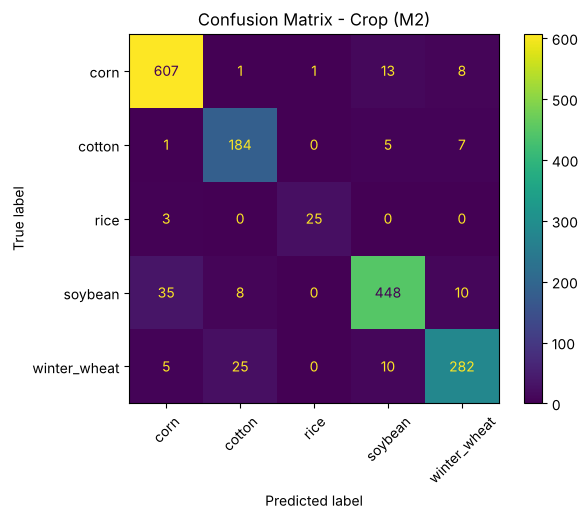

Stage - Modell: MLP (gemeinsames Label, +fe, getunt) - Balanced Accuracy: 0.902, Macro F1: 0.906
               precision    recall  f1-score   support

     Critical       0.94      0.95      0.95       462
    Early_Mid       0.89      0.89      0.89       295
Emerge_VEarly       0.90      0.90      0.90       312
      Harvest       0.88      0.83      0.86        54
         Late       0.97      0.97      0.97       258
Mature_Senesc       0.88      0.86      0.87       297

     accuracy                           0.92      1678
    macro avg       0.91      0.90      0.91      1678
 weighted avg       0.92      0.92      0.92      1678



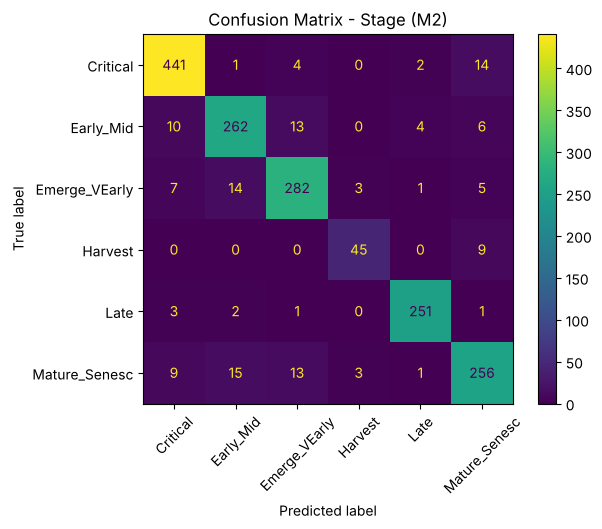

In [12]:
def predict_target(estimator, joint, target_name, X):
    pred = estimator.predict(X)
    return split_joint(pred)[0 if target_name == 'Crop' else 1] if joint else pred

for target_name, y_test_sel in [('Crop', y_crop_test), ('Stage', y_stage_test)]:
    info = best_per_target[target_name]
    pred = predict_target(info['best_estimator'], info['joint'], target_name, X_fe_test)

    bacc = balanced_accuracy_score(y_test_sel, pred)
    f1 = f1_score(y_test_sel, pred, average='macro')
    info['test_bacc'] = bacc
    info['test_f1'] = f1

    print(f"{target_name} - Modell: {info['label']} - Balanced Accuracy: {bacc:.3f}, Macro F1: {f1:.3f}")
    print(classification_report(y_test_sel, pred))

    ConfusionMatrixDisplay.from_predictions(y_test_sel, pred, xticks_rotation=45)
    plt.title(f'Confusion Matrix - {target_name} (M2)')
    plt.show()

**Alle getunten Kandidaten auf dem Test-Split** — nur zur Einordnung (die Auswahl oben erfolgte allein per CV).

In [13]:
test_rows = []
for (model_name, strat), info in tuned.items():
    for target_name, y_true in [('Crop', y_crop_test), ('Stage', y_stage_test)]:
        if target_name not in info['cv']:
            continue
        pred = predict_target(info['estimator'], strat == 'Joint', target_name, X_fe_test)
        test_rows.append({'target': target_name, 'model': model_name, 'strategie': 'gemeinsam' if strat == 'Joint' else 'separat',
                          'cv_bacc': info['cv'][target_name], 'test_bacc': balanced_accuracy_score(y_true, pred),
                          'test_f1_macro': f1_score(y_true, pred, average='macro')})
test_results = pd.DataFrame(test_rows).sort_values(['target', 'cv_bacc'], ascending=[True, False])
test_results.round(3)

,target,model,strategie,cv_bacc,test_bacc,test_f1_macro
2,Crop,MLP,separat,0.932,0.912,0.915
4,Crop,MLP,gemeinsam,0.929,0.924,0.928
0,Crop,HistGradientBoosting,separat,0.911,0.901,0.898
5,Stage,MLP,gemeinsam,0.910,0.902,0.906
3,Stage,MLP,separat,0.907,0.906,0.904
1,Stage,HistGradientBoosting,separat,0.891,0.896,0.897


## Zusammenfassung & Vergleich ggü. Baseline

In [14]:
rows = []
for target_name, m1_bacc, m1_f1, m2_bacc, m2_f1 in [('Crop', 0.778, 0.810, 0.877, 0.882), ('Stage', 0.769, 0.788, 0.874, 0.877)]:
    info = best_per_target[target_name]
    rows += [
        {'Zielgroesse': target_name, 'Modell': 'M1 Baseline (RandomForest)', 'Balanced Accuracy': m1_bacc, 'Macro F1': m1_f1},
        {'Zielgroesse': target_name, 'Modell': 'M2 ohne FE (HistGradientBoosting, Rohbaender)', 'Balanced Accuracy': m2_bacc, 'Macro F1': m2_f1},
        {'Zielgroesse': target_name, 'Modell': f"M2 final: {info['label']}",
         'Balanced Accuracy': info['test_bacc'], 'Macro F1': info['test_f1']},
    ]
summary = pd.DataFrame(rows)
summary.round(3)

,Zielgroesse,Modell,Balanced Accuracy,Macro F1
0,Crop,M1 Baseline (RandomForest),0.778,0.810
1,Crop,"M2 ohne FE (HistGradientBoosting, Rohbaender)",0.877,0.882
2,Crop,"M2 final: MLP (separat, +fe, getunt)",0.912,0.915
3,Stage,M1 Baseline (RandomForest),0.769,0.788
4,Stage,"M2 ohne FE (HistGradientBoosting, Rohbaender)",0.874,0.877
5,Stage,"M2 final: MLP (gemeinsames Label, +fe, getunt)",0.902,0.906


**Beobachtungen**

- **Mit fairem Tuning gewinnt das MLP.** Mit Default-Parametern liegt HistGradientBoosting vorne (CV Crop 0.899 vs. MLP 0.884, Stage 0.885 vs. 0.829). Bekommen aber beide Modelle dasselbe Tuning-Budget (30 Kombinationen, größeres Raster), dreht sich das: MLP Crop **0.932** vs. HGB 0.911, Stage **0.907–0.910** vs. 0.891 (CV). Der Testsplit bestätigt das (Crop 0.912–0.924 vs. 0.901, Stage 0.902–0.906 vs. 0.896). Das MLP profitiert viel stärker vom Tuning (+0.05 bis +0.08) als HGB (+0.01).
- **Warum das Tuning beim MLP so viel bringt:** Alle besten MLP-Konfigurationen nutzen `early_stopping=False`, 600 Epochen und eine kleine Lernrate (3e-4) mit breiten Schichten (512 Neuronen). `early_stopping=True` (Default oben) bricht zu früh ab und trainiert nur auf 90 % der Daten. Das alte, kleine Suchraster enthielt diese Einstellungen gar nicht.
- **Strategievergleich (separat vs. gemeinsames Label):** Getunt liegen beide MLP-Strategien praktisch gleichauf (CV Crop 0.932 vs. 0.929, Stage 0.907 vs. 0.910; Test Crop 0.912 vs. 0.924, Stage 0.906 vs. 0.902) — die Unterschiede liegen im Rauschen und wechseln das Vorzeichen zwischen CV und Test. Der frühere klare Vorteil des gemeinsamen Labels (0.909 vs. 0.884) kam vor allem daher, dass beide MLPs schlecht eingestellt waren. Praktischer Vorteil des gemeinsamen Modells: ein Modell statt zwei, und die Vorhersagen sind immer konsistent (keine unmöglichen Kombinationen wie `rice|Harvest`).
- **Gemeinsames HGB ist instabil:** In 3 von 5 Folds bricht es auf ~0.3 ein, in den anderen beiden erreicht es ~0.9 — vermutlich numerische Probleme bei 23 Klassen, von denen manche sehr klein sind (`cotton|Harvest`: 11 Zeilen). Deshalb wird es nicht weiter verfolgt.
- **Feature Engineering bringt messbar etwas (Ablation, CV, Default-Parameter):** HistGradientBoosting Crop 0.877 → **0.899**, Stage 0.854 → **0.885**; RandomForest Crop 0.827 → 0.872, Stage 0.793 → 0.829. Die Verbesserung liegt über der CV-Streuung (Std 0.008–0.03).
- **Overfitting-Check (gap = Train − CV, Default-Parameter):** Bäume haben erwartungsgemäß eine große Lücke (HGB ~0.10–0.15, RF ~0.13–0.21), der CV-Score ist aber hoch und stabil. Das MLP mit early stopping hat die kleinste Lücke (~0.04).
- **Zyklisches Month-Encoding bringt nichts:** Unterschied plain vs. zyklisch bei HGB ±0.002 und damit im Rauschen; `Month` läuft nur von 5 bis 10 ohne Jahreswechsel. Das FE-Set nutzt plain `Month`.
- **Split-Verhältnis spielt kaum eine Rolle:** 70/30, 80/20 und 90/10 liegen im Band 0.81–0.84 (leichter Anstieg mit mehr Trainingsdaten, aber auf kleinerem, verrauschterem Testset); wir bleiben bei 70/30.
- **Finale Testset-Ergebnisse (Auswahl per CV, Testsplit nie für CV/Tuning/Auswahl verwendet):** Crop Balanced Accuracy **0.912** (separates MLP; M1: 0.778), Macro F1 0.915. Stage Balanced Accuracy **0.902** (gemeinsames MLP; M1: 0.769), Macro F1 0.906.
- **Fehleranalyse:** Bei Crop ist jetzt `cotton` am schwächsten (F1 0.89), `rice` verbessert sich deutlich (F1 0.82 → 0.93, aber nur 28 Testfälle), `corn` bleibt am stärksten (0.95). Bei Stage sind `Harvest` (F1 0.86, nur 54 Testfälle) und `Mature_Senesc` (0.87) am schwächsten — benachbarte Reifephasen; `Late` am stärksten (0.97).
- **Einschränkungen:** Ein einziger Random Seed (MLP-Ergebnisse schwanken je nach Seed um ~0.01–0.02); `best_score_` aus der Suche ist als Maximum über 30 Kandidaten leicht optimistisch. Die Werte „M2 ohne FE“ in der Zusammenfassung stammen aus dem früheren Lauf. Mit anderen scikit-learn-Versionen weichen v. a. die RandomForest-Werte leicht ab.